# Predicting Live Hen Market Prices in Rwanda
**Mission:** Help Rwandan youth and small holder farmers succeed in poultry farming by guiding farm setup, flock care, vet access and profit tracking.

**use case:** predict the retail price(RWF) of a live hen in a given Rwandan market and month. Poultry farmers use this to decide where and when to sell their birds and to estimate income before going to market.

**Data used:** WFP(World Food Program) Food prices for Rwanda(Humanitarian Data Exchange) - real monthly msrket price surveys.

**1. Imports**

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

**2. Load the raw data**

In [16]:
raw = pd.read_csv('wfp_food_prices_rwa.csv')

#remove the second row tags like '#date' if it is present
raw = raw[~raw["date"].astype(str).str.startswith('#')].copy()
for col in ['price', 'latitude', 'longitude']:
    raw[col] = pd.to_numeric(raw[col])
print(raw.shape)
raw.head()

(157793, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


## Building the modeling table

The raw file has one row per (market, month, commodity). We keep only **retail live hen prices** as target, the add the price of other commodities **in the same market and month** as features:
- **Eggs** - the other main poultry product
- **Maize and soybeans** - the main ingredients in poultry feed (a cost signal)
- **Dry beans and beef** - general food price level in that market

**3. Building the table**

In [17]:
retail = raw[raw["pricetype"] == "Retail"]
hen = retail[retail["commodity"] == "Livestock (hen)"][
    ["date", "admin1", "admin2", "market", "latitude", "longitude", "price"]
].rename(columns={"admin1": "province", "admin2": "district", "price": "hen_price"})

other_commodities = {
    "Eggs": "egg_price",
    "Maize": "maize_price",
    "Soybeans": "soybean_price",
    "Beans (dry)": "beans_price",
    "Meat (beef)": "beef_price",
}

for commodity, new_col in other_commodities.items():
    prices = (retail[retail["commodity"] == commodity]
              .groupby(["market", "date"])["price"].mean()
              .rename(new_col).reset_index())
    hen = hen.merge(prices, on=["market", "date"], how="left")

hen["date"] = pd.to_datetime(hen["date"])
hen["year"] = hen["date"].dt.year
hen["month"] = hen["date"].dt.month

print(hen.shape)
hen.head()

(1949, 14)


,date,province,district,market,latitude,longitude,hen_price,egg_price,maize_price,soybean_price,beans_price,beef_price,year,month
0,2012-01-15,Eastern Province,Bugesera,Nyamata,-2.21,30.24,2425.00,88.75,225.00,350.00,212.50,1625.00,2012,1
1,2012-01-15,Eastern Province,Bugesera,Ruhuha,-2.15,30.09,2500.00,78.75,250.00,400.00,200.00,1500.00,2012,1
2,2012-01-15,Eastern Province,Gatsibo,Kimironko,-1.75,30.34,3166.88,78.88,300.00,454.25,301.75,2124.75,2012,1
3,2012-01-15,Eastern Province,Gatsibo,Rwagitima,-1.80,30.42,4366.40,79.40,171.50,328.00,224.60,1533.33,2012,1
4,2012-01-15,Eastern Province,Kayonza,Kabarondo,-2.02,30.55,4450.25,93.75,281.25,383.25,197.50,1600.00,2012,1


**4. Handling missing values and outliers**

In [18]:
print("Missing values per column:\n", hen.isna().sum())

df = hen.dropna().copy()
print("\nAfter dropping missing rows:", df.shape)

# A few hen prices are 2-3x the normal range (likely data-entry errors)
print("\nHighest hen prices:\n", df["hen_price"].sort_values().tail(6).values)
df = df[df["hen_price"] <= 8000]
print("After removing extreme outliers:", df.shape)

df["hen_price"].describe()

Missing values per column:
 date               0
province           0
district           0
market             0
latitude           0
longitude          0
hen_price          0
egg_price         28
maize_price      136
soybean_price    149
beans_price        0
beef_price        54
year               0
month              0
dtype: int64

After dropping missing rows: (1643, 14)

Highest hen prices:
 [ 6750.    6833.33  8958.25  9966.8  11625.75 13399.8 ]
After removing extreme outliers: (1639, 14)


count    1639.000000
mean     3895.236693
std       694.142965
min      2000.000000
25%      3500.000000
50%      3950.000000
75%      4333.000000
max      6833.330000
Name: hen_price, dtype: float64

**5. Visual 1: Target Distribution and price per province**

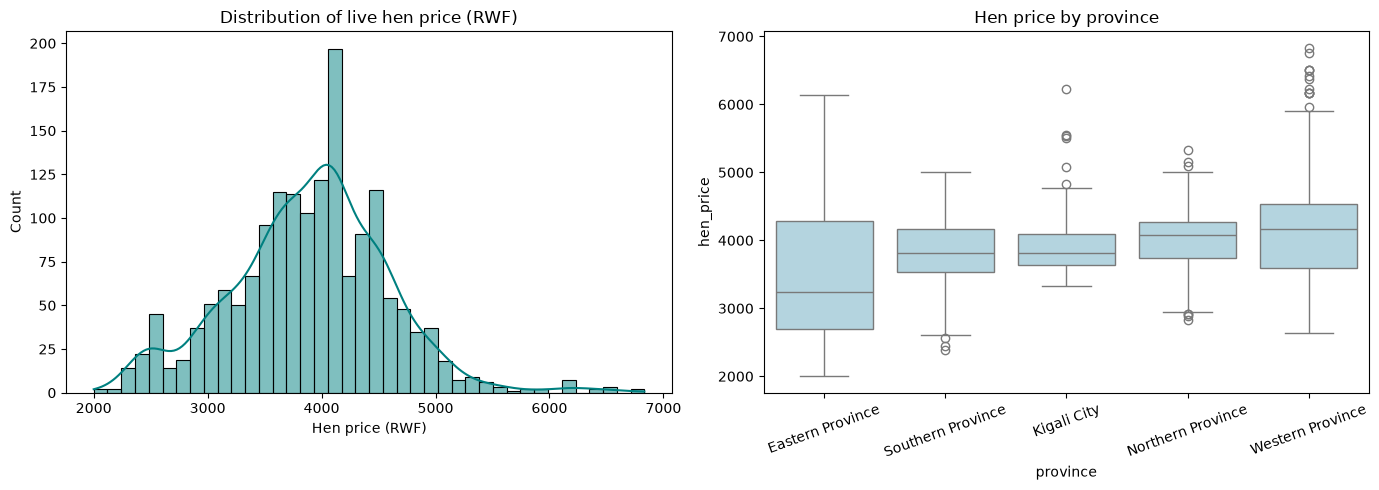

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["hen_price"], bins=40, kde=True, ax=axes[0], color="teal")
axes[0].set_title("Distribution of live hen price (RWF)")
axes[0].set_xlabel("Hen price (RWF)")

order = df.groupby("province")["hen_price"].mean().sort_values().index
sns.boxplot(data=df, x="province", y="hen_price", order=order, ax=axes[1], color="lightblue")
axes[1].set_title("Hen price by province")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**What it shows:** Hen prices are roughly bell-shaped around 3,900 RWF (most between 3,500 and 4,300) with very little skew, so no log transform of the target is needed. Prices differ clearly by province: Eastern Province is cheapest (~3,490 RWF on average) and Western Province most expensive (~4,190 RWF).

**Decision:** Removing the 4 extreme prices (>8,000 RWF) was justified since they sit far outside this distribution. Because location clearly matters, we keep **province and district** as categorical features and encode them for the models.

**6. Visual 2: Correlation heatmap**

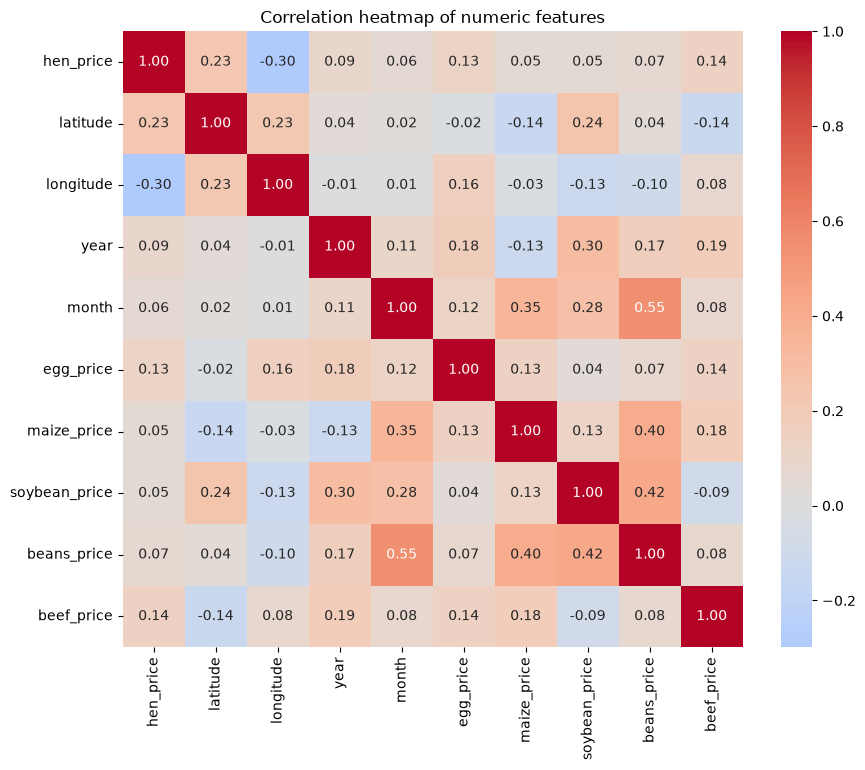

In [20]:
num_cols = ["hen_price", "latitude", "longitude", "year", "month",
            "egg_price", "maize_price", "soybean_price", "beans_price", "beef_price"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features")
plt.show()

**What it shows:** No single feature is strongly correlated with hen price. The strongest is **longitude (-0.30)** - prices fall as you move east - followed by latitude (0.23), beef price (0.14) and egg price (0.13). Feed prices (maize 0.05, soybean 0.05) have weak direct links. Feature-to-feature correlations are moderate at most (the highest is 0.55 between month and beans price, a seasonal harvest effect), so there is no serious multicollinearity.

**Decision:** Because relationships are weak and likely non-linear (location * season * local food prices), we expect **tree-based models to beat linear regression**. We keep all these features since none is redundant, and use **longitude** for the single-feature scatter plots later.

## Feature engineering

**Dropped columns and why:**
- `market_id`, `commodity_id`, `category`, `commodity`, `unit`, `currency`, `pricetype`, `priceflag` - identifiers or constant after filtering (all rows are retail, RWF, live hen)
- `usdprice` - the same price in another currency; using it would leak the target
- `market` - 60 values, already captured by district + latitude/longitude
- `date` - replaced by `year` and `month`

**Final features (11):** province, district (categorical) + latitude, longitude, year, month, egg_price, maize_price, soybean_price, beans_price, beef_price (numeric).

**Most important for the target:** location (longitude, latitude, province, district), then local food price levels (beef and egg prices).